# 08 · Tuning P3: alarm rules

What [`reports/method_research.md`](../reports/method_research.md) asked to tune:
- alarm on the **share of never-seen categorical values** instead of JS;
- alarm on the **number of columns** flagged by the PSI test, not on any single column;
- set the **V-block missing-rate** threshold;
- remove **time-trend columns** from the domain classifier, which otherwise separates every week.

**Design.** Thresholds need examples of "nothing happened" and of "something happened":
- *Clean weeks*: weeks without a known or suspected change. Tuning: 8, 10, 11, 12, 15, 16. Validation: 17, 19, 20, 21. Weeks 4, 9 and 22 (known events) and 13, 14, 18, 23-25 (changes found in notebook 05) are excluded.
- *Injected drift*: known synthetic changes put into clean weeks (pipeline breakage, covariate shift, new category values, prior shift, concept shift), at two intensities each.

Thresholds are set on the **tuning** clean weeks only (at most 1 alarm in 10 clean weeks, per rule). Detection is then measured on the **validation** weeks and on the real events. Every week is compared with the 4 weeks before it, as in notebook 05.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud.analysis import near_constant
from fraud.config import load_config
from fraud.data import ENTITY_COL, ID_COL, PROCESSED_DIR, TARGET, TIME_COL, load_dataset
from fraud.drift import ALARM_STATS, apply_alarm_rules, choose_thresholds, inject_drift, monitor_week, trend_columns
from fraud.features import is_categorical
from fraud.profiling import column_group, missing_blocks

cfg = load_config("monitoring")
FIG_DIR = Path("../reports/figures")
TUNE_CLEAN, VALID_CLEAN = [8, 10, 11, 12, 15, 16], [17, 19, 20, 21]
KNOWN_EVENTS = {4: "V-block missing step", 9: "browser release", 22: "browser release"}

df = load_dataset("train")
inputs = [c for c in df.columns if c not in (ID_COL, TARGET, TIME_COL, "timestamp", "day", "week", "month", ENTITY_COL)]
constant = set(near_constant(df, inputs).index)
numeric = [c for c in inputs if not is_categorical(df[c]) and c not in constant]
categorical = [c for c in inputs if is_categorical(df[c]) and c not in constant]
V = [c for c in inputs if column_group(c) == "V1-V339"]
blocks = missing_blocks(df, V)
block_columns = {f"{b['first']}-{b['last']}": b["first"] for _, b in blocks.iterrows()}

# Decided on the tuning period only. Few columns trend strongly (3 above |rho| = 0.3), so the
# cut is 0.1; the domain-classifier threshold is then set relative to clean weeks anyway.
trend = trend_columns(df[df["week"] <= 16], numeric, threshold=0.1)
domain_columns = [c for c in numeric if c not in trend] + categorical
print(f"{len(trend)} numeric columns move with time (|Spearman rho| > 0.1), e.g. {trend[:8]}; the domain classifier uses the other {len(domain_columns)}")

injected_block = blocks.loc[blocks["missing_rate"].idxmin(), "columns"]  # a block that is normally always present
SCENARIOS = [("pipeline", 0.1), ("pipeline", 0.3), ("covariate", 0.1), ("covariate", 0.3), ("new_category", 0.05),
             ("new_category", 0.15), ("prior", 0.5), ("prior", 1.0), ("concept", 0.2)]
print(f"pipeline scenario breaks block {injected_block[0]}-{injected_block[-1]} ({len(injected_block)} columns)")

62 numeric columns move with time (|Spearman rho| > 0.1), e.g. ['C4', 'C8', 'C9', 'C10', 'D8', 'V139', 'V140', 'V143']; the domain classifier uses the other 345
pipeline scenario breaks block V279-V321 (32 columns)


In [2]:
def run(week, scenario=None, intensity=0.0, seed=0):
    reference = df[(df["week"] >= week - 4) & (df["week"] < week)]
    current = df[df["week"] == week]
    if scenario:
        current = inject_drift(current, scenario, intensity, np.random.default_rng(seed), block=injected_block)
    row = monitor_week(reference, current, numeric, categorical, block_columns, cfg, run_domain=True,
                       seed=seed, run_ks=False, domain_columns=domain_columns)
    return {"week": week, "scenario": scenario or "none", "intensity": intensity, **row}

path = PROCESSED_DIR / "tuning_monitor_runs.parquet"
if path.exists():
    runs = pd.read_parquet(path)
else:
    rows = [run(w) for w in TUNE_CLEAN + VALID_CLEAN + sorted(KNOWN_EVENTS)]
    for w in TUNE_CLEAN + VALID_CLEAN:
        for scenario, intensity in SCENARIOS:
            rows.append(run(w, scenario, intensity, seed=w))
    runs = pd.DataFrame(rows)
    runs.to_parquet(path)
runs["split"] = np.where(runs["week"].isin(TUNE_CLEAN), "tune", np.where(runs["week"].isin(VALID_CLEAN), "valid", "event"))
print(f"{len(runs)} monitor runs")

103 monitor runs


## Thresholds from the tuning clean weeks

In [3]:
clean_tune = runs[(runs["scenario"] == "none") & (runs["split"] == "tune")]
thresholds = choose_thresholds(clean_tune, max_false_alarm=0.1, margin=1.1)
before = {"new_values": None, "psi_columns": 0, "block_missing": cfg["null_rate"]["effect_threshold"], "domain": cfg["domain_classifier"]["alarm_auc"]}
pd.DataFrame({"statistic": ALARM_STATS, "clean tuning weeks (min-max)": {
    r: f"{clean_tune[c].astype(float).min():.3f}-{clean_tune[c].astype(float).max():.3f}" for r, c in ALARM_STATS.items()},
    "threshold before": before, "tuned threshold": thresholds}).round(3)

,statistic,clean tuning weeks (min-max),threshold before,tuned threshold
new_values,max_new_share,0.036-0.054,NaN,0.058
psi_columns,psi_test_flagged,0.000-2.000,0.0,2.200
block_missing,max_block_shift,0.036-0.095,0.1,0.097
domain,domain_auc,0.700-0.747,0.6,0.815


In [4]:
alarms = apply_alarm_rules(runs, thresholds)
runs_alarm = pd.concat([runs[["week", "scenario", "intensity", "split"]], alarms], axis=1)

clean_valid = runs_alarm[(runs_alarm["scenario"] == "none") & (runs_alarm["split"] == "valid")]
print(f"false alarms on the {len(clean_valid)} validation clean weeks: {int(clean_valid['any'].sum())}")
detect = (runs_alarm[runs_alarm["scenario"] != "none"]
          .groupby(["scenario", "intensity", "split"])[list(thresholds) + ["any"]].mean()
          .unstack("split"))
detect_valid = detect.xs("valid", axis=1, level=1)
print("Detection rate on the validation weeks (share of injected weeks with an alarm)")
detect_valid.round(2)

false alarms on the 4 validation clean weeks: 0
Detection rate on the validation weeks (share of injected weeks with an alarm)


new_values  psi_columns  block_missing  domain   any
scenario     intensity                                                      
concept      0.20             0.00         0.00            0.0     0.0  0.00
covariate    0.10             0.00         0.00            0.0     1.0  1.00
             0.30             0.00         0.25            0.0     1.0  1.00
new_category 0.05             0.00         0.00            0.0     0.0  0.00
             0.15             1.00         0.00            0.0     0.0  1.00
pipeline     0.10             0.00         0.00            1.0     0.0  1.00
             0.30             0.00         0.00            1.0     0.0  1.00
prior        0.50             0.25         0.00            0.0     0.0  0.25
             1.00             0.25         0.00            0.0     0.0  0.25

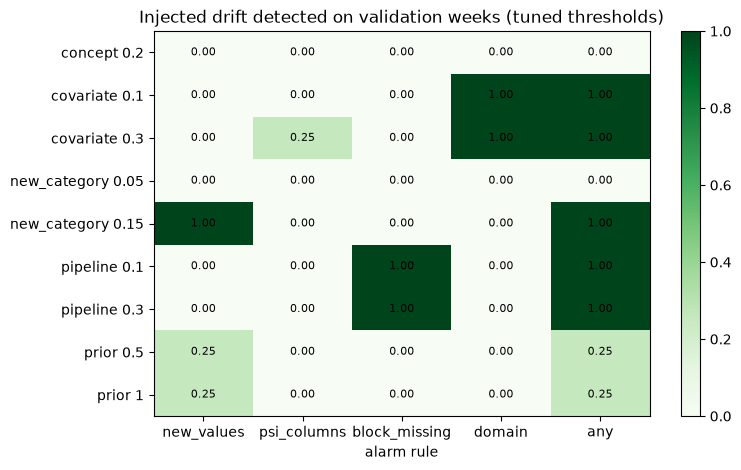

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
m = detect_valid.copy()
m.index = [f"{s} {i:g}" for s, i in m.index]
im = ax.imshow(m, cmap="Greens", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(m.shape[1]), m.columns)
ax.set_yticks(range(m.shape[0]), m.index)
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        ax.annotate(f"{m.iat[i, j]:.2f}", (j, i), ha="center", va="center", fontsize=8)
ax.set(title="Injected drift detected on validation weeks (tuned thresholds)", xlabel="alarm rule")
fig.colorbar(im, ax=ax)
fig.savefig(FIG_DIR / "tu_detection.png", dpi=120, bbox_inches="tight")

## Replay on every week 4-25 with the tuned rules

In [6]:
replay_path = PROCESSED_DIR / "tuning_monitor_replay.parquet"
if replay_path.exists():
    replay = pd.read_parquet(replay_path)
else:
    replay = pd.DataFrame([run(w) for w in range(4, 26)]).set_index("week")
    replay.to_parquet(replay_path)
replay_alarms = apply_alarm_rules(replay, thresholds)
status = pd.Series("clean (tuning)", index=replay.index)
status[status.index.isin(VALID_CLEAN)] = "clean (validation)"
status[status.index.isin([13, 14, 18, 23, 24, 25])] = "change found in notebook 05"
for w, name in KNOWN_EVENTS.items():
    status[w] = f"known event: {name}"
status[status.index.isin([5, 6, 7])] = "after week-4 step"
table = pd.concat([status.rename("week type"), replay[list(ALARM_STATS.values())].astype(float).round(3), replay_alarms], axis=1)
table

,week type,max_new_share,psi_test_flagged,max_block_shift,domain_auc,new_values,psi_columns,block_missing,domain,any
week,,,,,,,,,,
4,known event: V-block missing step,0.031,21.0,0.246,0.742,False,True,True,False,True
5,after week-4 step,0.034,22.0,0.249,0.734,False,True,True,False,True
6,after week-4 step,0.021,17.0,0.258,0.774,False,True,True,False,True
7,after week-4 step,0.031,10.0,0.162,0.753,False,True,True,False,True
8,clean (tuning),0.038,2.0,0.036,0.700,False,False,False,False,False
9,known event: browser release,0.186,0.0,0.074,0.737,True,False,False,False,True
10,clean (tuning),0.036,1.0,0.061,0.734,False,False,False,False,False
11,clean (tuning),0.054,1.0,0.081,0.717,False,False,False,False,False
12,clean (tuning),0.049,1.0,0.054,0.716,False,False,False,False,False


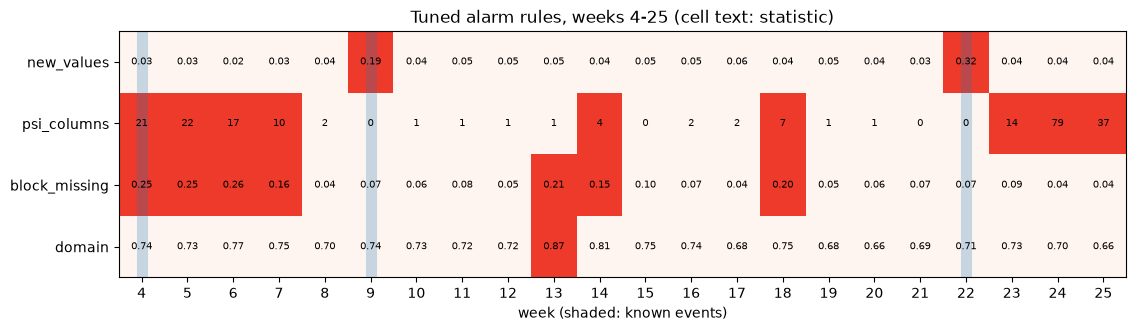

In [7]:
fig, ax = plt.subplots(figsize=(13, 3.2))
shown = replay_alarms[list(thresholds)].T.astype(int)
ax.imshow(shown, cmap="Reds", aspect="auto", vmin=0, vmax=1.6)
ax.set_xticks(range(shown.shape[1]), shown.columns)
ax.set_yticks(range(shown.shape[0]), shown.index)
stat_cols = list(ALARM_STATS.values())
for i, col in enumerate(stat_cols[: shown.shape[0]]):
    for j, v in enumerate(replay[col].astype(float)):
        ax.annotate(f"{v:.2f}" if col != "psi_test_flagged" else f"{int(v)}", (j, i), ha="center", va="center", fontsize=7)
for w in KNOWN_EVENTS:
    ax.axvline(shown.columns.get_loc(w), color="C0", lw=8, alpha=.25)
ax.set(xlabel="week (shaded: known events)", title="Tuned alarm rules, weeks 4-25 (cell text: statistic)")
fig.savefig(FIG_DIR / "tu_replay.png", dpi=120, bbox_inches="tight")

In [8]:
# Concept shift: labels change, features do not, so every label-free statistic equals the clean week.
concept = runs[runs["scenario"] == "concept"].set_index("week")
clean_all = runs[runs["scenario"] == "none"].set_index("week").loc[concept.index]
same = all(np.allclose(concept[c].astype(float), clean_all[c].astype(float)) for c in ["max_new_share", "psi_test_flagged", "max_block_shift"])
print("concept shift leaves the label-free statistics unchanged:", same)
print("tuned thresholds:", {k: round(v, 4) for k, v in thresholds.items()})

concept shift leaves the label-free statistics unchanged: True
tuned thresholds: {'new_values': 0.0577, 'psi_columns': 2.2, 'block_missing': 0.0967, 'domain': 0.815}
